# SLATE demo

This notebook shows what goes into SLATE and what comes out, on one recording of the public ETDD70 dataset: a child reading a seven-line text aloud, recorded at 250 Hz with a laboratory eye tracker. The recording is first given the errors we measured in tablet-camera gaze (the tablet-like degradation of the paper), and SLATE is run on that signal.

To run it yourself, install the packages listed in the README and open this file from the `examples/` folder.

In [1]:
import sys
sys.path.insert(0, "..")   # the repository root

import numpy as np
from IPython.display import HTML

from slate import correct_fixations
from examples import demo

trial = demo.load_trial()
samples, fixations = trial["samples"], trial["fixations"]
print(f"{len(samples['t'])} gaze samples over {samples['t'][-1]:.0f} s, {len(fixations)} fixations, {len(trial['line_Y'])} text lines")

28655 gaze samples over 115 s, 221 fixations, 7 text lines


## 1. The input

On the left is the recording as published: every dot is a fixation, colored by the line it was on according to the dataset, and the gray bars are the text lines. On the right is the same recording with the tablet-like degradation applied: resampled to 29.4 Hz, compressed, displaced, and with the slow vertical drift and the within-line slope measured in our tablet recordings. The signal on the right is what SLATE receives.

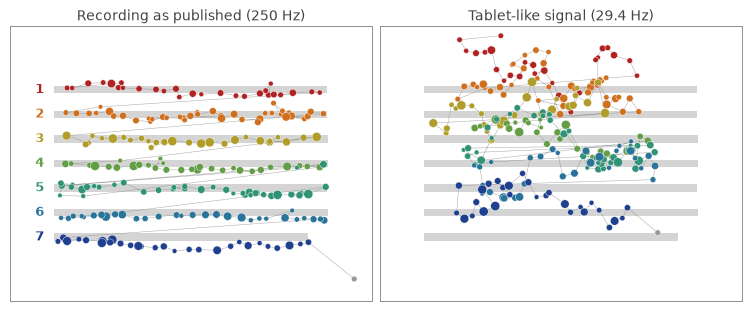

In [2]:
original = demo.run(trial, "original")
tablet = demo.run(trial, "tablet-like")
fig = demo.figure_degradation(trial, original, tablet)

In the tablet-like signal the fixations of different lines overlap, and the whole recording has moved away from the text, so the nearest text line is no longer the line being read:

In [3]:
for name, r in (("as published", original), ("tablet-like", tablet)):
    print(f"{name:13s} nearest text line: {100 * r['accuracy']['nearest']:5.1f}% of fixations on the labeled line")

as published  nearest text line:  98.6% of fixations on the labeled line
tablet-like   nearest text line:  19.5% of fixations on the labeled line


## 2. Running SLATE

`correct_fixations` takes the gaze samples (times and horizontal position), the fixations and the positions of the text lines. It finds the line transitions in the horizontal coordinate, assigns every fixation to a line and recalibrates the horizontal position. The vertical coordinate is not used, and the threshold for a return sweep is set from the horizontal range of this recording, so the same settings are used for every recording.

It returns one row per fixation, with the recorded values kept and the line and the corrected position added.

In [4]:
t, x = tablet["t"], tablet["x"]          # gaze samples of the tablet-like signal
lines = demo.text_lines(trial)           # edges, vertical position and number of words of each line

table = correct_fixations(tablet["observed"], t, x, lines, first_at_start=True)
table.to_csv("corrected_fixations.csv", index=False)

print(f"{100 * np.mean(table.line == tablet['truth']):.1f}% of fixations on the labeled line")
table.round(1).head(8)

99.1% of fixations on the labeled line


,start,end,x,y,line,x_corrected,y_corrected
0,0.0,0.3,577.1,-3.8,1,524.5,198.5
1,0.3,0.6,396.1,11.1,1,247.9,198.5
2,0.6,0.8,425.0,52.7,1,292.0,198.5
3,0.8,1.3,468.3,61.3,1,358.2,198.5
4,1.3,1.6,507.6,58.2,1,418.3,198.5
5,1.6,2.5,535.8,50.1,1,461.4,198.5
6,2.5,2.9,558.3,123.0,1,495.8,198.5
7,2.9,3.1,591.5,164.6,1,546.5,198.5


## 3. The result

On the left are the fixations as recorded in the tablet-like signal. On the right are the same fixations at the corrected positions of the table above: each one on its assigned line, at its recalibrated horizontal position.

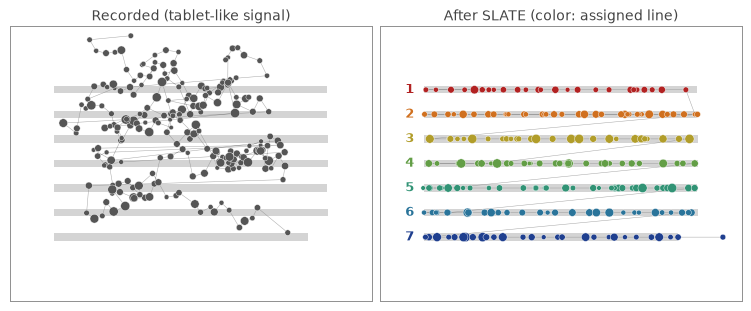

In [5]:
fig = demo.figure_before_after(trial, tablet)

The corrected fixations span the full width of each text line because the end of a line is mapped to the right edge of the text by default. Where the last fixation of a line falls varies between readers and texts, so this target can be adjusted with `alpha` (in widths of the last word). It is 0 here, as in the paper.

The same result over time. The trace is the horizontal position, colored by the line SLATE assigned, and the dashed lines are the line transitions it found. The three bands underneath show the line of every fixation as labeled in the dataset, as assigned by SLATE, and as assigned by the nearest text line.

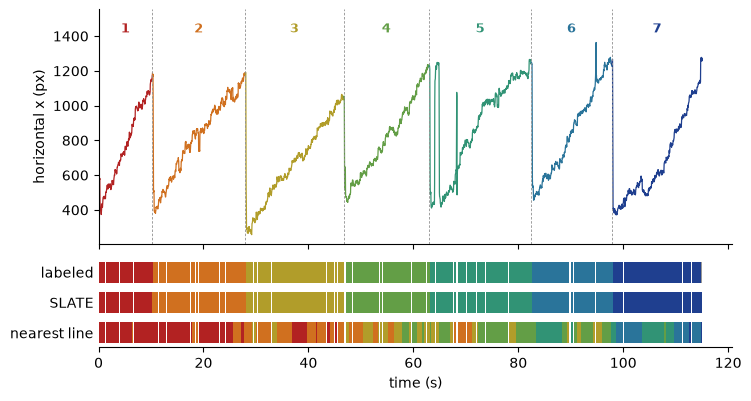

In [6]:
fig = demo.figure_transitions(trial, tablet)

And as a replay of the reading, at twice the speed:


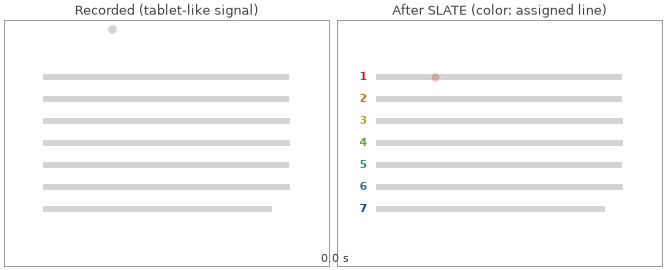

In [7]:
gif = demo.animate_before_after(trial, tablet, "before_after.gif", speed=2.0)
HTML(demo.embedded(gif))

## Using your own recording

`correct_fixations` needs your fixations, the gaze samples (times in seconds and horizontal position) and the positions of the text lines. The README describes the inputs, the speech-based step and the recalibration. If the recording contains gaze from before the reader starts on the text, we recommend leaving it out, because the start of reading is not detected when `first_at_start=True` is used.